In [164]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
TH99=0.14655972998295605
TH95=0.10024662155621214
# df must contain:
# patient_id, risk_t0, screen_date, event_date
# screen_date and event_date are integers on the same time scale
# event_date can be missing if event never occurred

def make_km_plot(
    df,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_t0",
    max_followup=5,
    risk_split="median",   # "median", numeric threshold, or None
    title="Kaplan-Meier curve",
    time_unit_label="Time since screening"
):
    d = df.copy()

    # Coerce to numeric
    d[screen_col] = pd.to_numeric(d[screen_col], errors="coerce")
    d[event_col] = pd.to_numeric(d[event_col], errors="coerce")
    d[risk_col] = pd.to_numeric(d[risk_col], errors="coerce")

    # Drop rows with invalid screening time or missing risk
    d = d[d[screen_col].notna() & d[risk_col].notna()].copy()

    # Time from screening to event
    time_to_event = d[event_col] - d[screen_col]

    # Event observed only if:
    #   event exists
    #   event_date >= screen_date
    #   event occurs within follow-up window
    d["event_observed"] = (
        d[event_col].notna() &
        (d[event_col] >= d[screen_col]) &
        (time_to_event <= max_followup)
    ).astype(int)

    # Observed time:
    # actual time if valid observed event, otherwise censor at max_followup
    d["time"] = np.where(
        d["event_observed"] == 1,
        time_to_event,
        max_followup
    )

    # Remove negative observed/censor times if any weird rows remain
    d = d[d["time"] >= 0].copy()

    plt.figure(figsize=(8, 6))
    kmf = KaplanMeierFitter()

    if risk_split == "median":
        thr = d[risk_col].median()
        d["risk_group"] = np.where(d[risk_col] >= thr, "High risk", "Low risk")

        for grp in ["High risk", "Low risk"]:
            sub = d[d["risk_group"] == grp]
            if len(sub) == 0:
                continue
            kmf.fit(
                durations=sub["time"],
                event_observed=sub["event_observed"],
                label=f"{grp} (n={len(sub)})"
            )
            kmf.plot_survival_function(ci_show=True)

        plt.title(f"{title}\nSplit at median {risk_col} = {thr:.4f}")

    elif isinstance(risk_split, (int, float)):
        thr = float(risk_split)
        d["risk_group"] = np.where(d[risk_col] >= thr, "High risk", "Low risk")

        for grp in ["High risk", "Low risk"]:
            sub = d[d["risk_group"] == grp]
            if len(sub) == 0:
                continue
            kmf.fit(
                durations=sub["time"],
                event_observed=sub["event_observed"],
                label=f"{grp} (n={len(sub)})"
            )
            kmf.plot_survival_function(ci_show=True)

        plt.title(f"{title}\nSplit at {risk_col} = {thr:.4f}")

    else:
        kmf.fit(
            durations=d["time"],
            event_observed=d["event_observed"],
            label="All patients"
        )
        kmf.plot_survival_function(ci_show=True)
        plt.title(title)

    plt.xlim(0, max_followup)
    plt.xlabel(time_unit_label)
    plt.ylabel("Event-free survival probability")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return d


# Example:
# processed_df = make_km_plot(
#     df,
#     screen_col="t0",
#     event_col="event_t",
#     risk_col="risk",
#     max_followup=5,
#     risk_split="median",
#     time_unit_label="Months since screening"
# )

In [165]:
from lifelines.statistics import logrank_test

def logrank_high_low(processed_df):
    g1 = processed_df[processed_df["risk_group"] == "High risk"]
    g0 = processed_df[processed_df["risk_group"] == "Low risk"]

    res = logrank_test(
        g1["time_months"], g0["time_months"],
        event_observed_A=g1["event_observed"],
        event_observed_B=g0["event_observed"]
    )
    print(res.summary)
    return res

    

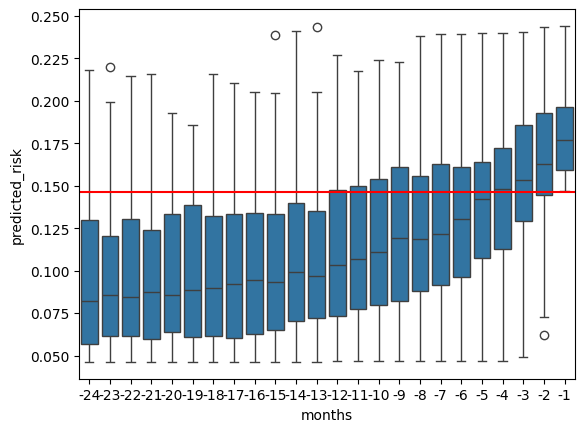

In [166]:
import pandas as pd
import seaborn as sns
import pylab as plt
df=pd.read_csv('./violin_plots_data.csv')
sns.boxplot(data=df,x='months',y='predicted_risk')
plt.axhline(0.14655972998295605,c='r')

In [167]:
import pandas as pd
import numpy as np


def make_screen_event_df_all(
    df,
    risk_threshold,
    patient_col="patient_id",
    month_col="months",
    risk_col="predicted_risk",
):
    df = df.copy()
    df = df.sort_values([patient_col, month_col])

    rows = []

    for pid, g in df.groupby(patient_col, sort=False):
        g = g.sort_values(month_col)

        g0 = g[g[month_col] == -1]
        risk_t0 = g0[risk_col].iloc[0] if not g0.empty else np.nan

        crossed = g[g[risk_col] > risk_threshold]
        screen_date = crossed[month_col].iloc[0] if not crossed.empty else np.nan

        rows.append({
            "patient_id": pid,
            "risk_t0": risk_t0,
            "screen_date": screen_date,
            "event_date": -1
        })

    return pd.DataFrame(rows)

In [263]:
import pandas as pd
import numpy as np

def make_screen_event_df_all(
    df,
    risk_threshold,
    patient_col="patient_id",
    month_col="months",
    risk_col="predicted_risk",
):
    df = df.copy()
    df = df.sort_values([patient_col, month_col])

    rows = []

    for pid, g in df.groupby(patient_col, sort=False):
        g = g.sort_values(month_col).reset_index(drop=True)

        crossed = g[g[risk_col] > risk_threshold]

        if crossed.empty:
            continue

        first_idx = crossed.index[0]

        screen_date = g.loc[first_idx, month_col]
        risk_crossing = g.loc[first_idx, risk_col]

        if first_idx > 0:
            risk_prev = g.loc[first_idx - 1, risk_col]
        else:
            risk_prev = np.nan

        delta_1 = risk_crossing - risk_prev if pd.notna(risk_prev) else np.nan

        rows.append({
            "patient_id": pid,
            "screen_date": screen_date,
            "event_date": -1,
            "risk_crossing": risk_crossing,
            "risk_prev": risk_prev,
            "delta_1": delta_1
        })

    return pd.DataFrame(rows)

def add_dynamic_risk_score(df):
    df = df.copy()

    rc = df["risk_crossing"]
    d1 = df["delta_1"]

    rc_z = (rc - rc.mean()) / rc.std()
    d1_z = (d1 - d1.mean()) / d1.std()

    df["risk_dynamic"] = rc_z + d1_z

    return df    




def redefine_risk_with_delta(
    df,
    level_col="risk_crossing",
    delta_col="delta_1",
    alpha=1.0,
):
    """
    Redefine risk_crossing to depend on both level and increase.

    new risk_crossing =
        z(level) + alpha * z(delta)

    alpha controls how strongly recent increase influences risk.
    alpha = 1.0 gives equal weight.
    """

    d = df.copy()

    d.risk_crossing = 0*(d.risk_prev) + 1*d.risk_crossing

    return d

In [264]:
df_=make_screen_event_df_all(df,risk_threshold=TH99)
df_['event_date'] = df_.event_date-df_.screen_date
df_.screen_date = 0
#df_=df_.fillna(0)
#df_['newrisk'] = df_.risk_crossing/df_.delta_1
df_

,patient_id,screen_date,event_date,risk_crossing,risk_prev,delta_1
0,1.018601e+06,0,0,0.149543,0.127247,0.022296
1,2.778300e+07,0,4,0.164255,0.103837,0.060418
2,1.396464e+08,0,20,0.160798,0.146397,0.014401
3,2.126150e+08,0,0,0.159715,0.117652,0.042063
4,5.350068e+08,0,23,0.177268,NaN,NaN
...,...,...,...,...,...,...
99,3.190233e+10,0,5,0.152709,0.084557,0.068152
100,3.190311e+10,0,8,0.157316,0.100319,0.056998
101,3.190329e+10,0,0,0.199062,0.104453,0.094609
102,3.194395e+10,0,12,0.150285,0.114721,0.035564


In [265]:
df_ = redefine_risk_with_delta(
    df_,
    level_col="risk_crossing",
    delta_col="delta_1",
    alpha=1.0
)
df_

,patient_id,screen_date,event_date,risk_crossing,risk_prev,delta_1
0,1.018601e+06,0,0,0.149543,0.127247,0.022296
1,2.778300e+07,0,4,0.164255,0.103837,0.060418
2,1.396464e+08,0,20,0.160798,0.146397,0.014401
3,2.126150e+08,0,0,0.159715,0.117652,0.042063
4,5.350068e+08,0,23,NaN,NaN,NaN
...,...,...,...,...,...,...
99,3.190233e+10,0,5,0.152709,0.084557,0.068152
100,3.190311e+10,0,8,0.157316,0.100319,0.056998
101,3.190329e+10,0,0,0.199062,0.104453,0.094609
102,3.194395e+10,0,12,0.150285,0.114721,0.035564


In [266]:
df_.delta_1.max()

0.1103570143555466

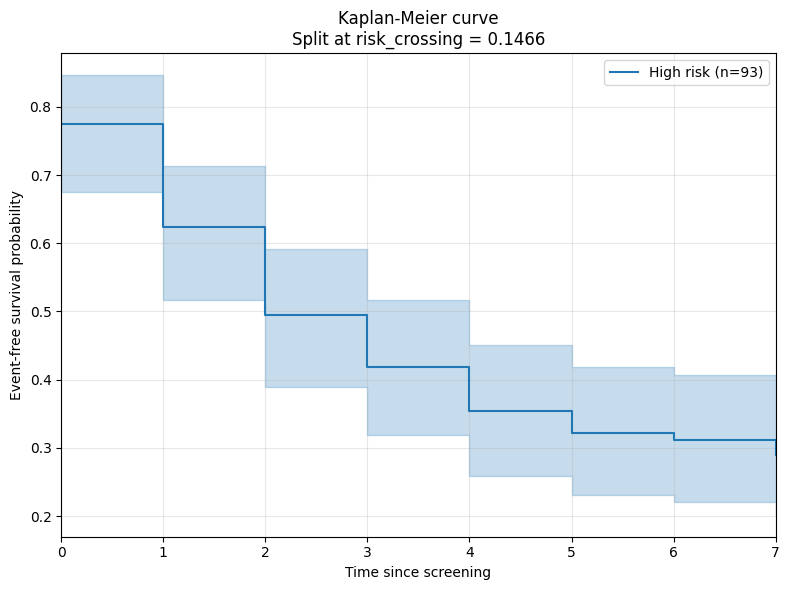

In [267]:
processed_df=make_km_plot(
    df_,
    screen_col="screen_date",
    event_col="event_date",
    risk_col="risk_crossing",
    max_followup=7,
    risk_split=TH99,#"median",   # "median", numeric threshold, or None
    title="Kaplan-Meier curve")

In [172]:
processed_df

,patient_id,screen_date,event_date,risk_crossing,risk_prev,delta_1,event_observed,time,risk_group
0,1.018601e+06,0,0,0.149543,0.127247,0.022296,1,0,High risk
1,2.778300e+07,0,4,0.164255,0.103837,0.060418,1,4,High risk
2,1.396464e+08,0,20,0.160798,0.146397,0.014401,0,7,High risk
3,2.126150e+08,0,0,0.159715,0.117652,0.042063,1,0,High risk
4,5.350068e+08,0,23,0.177268,NaN,NaN,0,7,High risk
...,...,...,...,...,...,...,...,...,...
99,3.190233e+10,0,5,0.152709,0.084557,0.068152,1,5,High risk
100,3.190311e+10,0,8,0.157316,0.100319,0.056998,0,7,High risk
101,3.190329e+10,0,0,0.199062,0.104453,0.094609,1,0,High risk
102,3.194395e+10,0,12,0.150285,0.114721,0.035564,0,7,High risk


In [148]:
from lifelines.statistics import logrank_test

def logrank_high_low(processed_df):
    g1 = processed_df[processed_df["risk_group"] == "High risk"]
    g0 = processed_df[processed_df["risk_group"] == "Low risk"]

    res = logrank_test(
        g1["time"], g0["time"],
        event_observed_A=g1["event_observed"],
        event_observed_B=g0["event_observed"]
    )
    print(res.summary)
    return res

    

In [149]:
logrank_high_low(processed_df)

   test_statistic         p  -log2(p)
0        0.102663  0.748657  0.417623


<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           0.10 0.75      0.42

In [150]:
print(processed_df.groupby("risk_group")["event_observed"].mean())


risk_group
High risk    0.647059
Low risk     0.578947
Name: event_observed, dtype: float64


In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def compute_discrete_hazard(df, time_col="time", event_col="event_observed"):
    df = df.copy()

    times = np.sort(df[time_col].unique())

    at_risk = []
    events = []
    hazard = []

    for t in times:
        n_risk = (df[time_col] >= t).sum()
        n_events = ((df[time_col] == t) & (df[event_col] == 1)).sum()

        h = n_events / n_risk if n_risk > 0 else np.nan

        at_risk.append(n_risk)
        events.append(n_events)
        hazard.append(h)

    out = pd.DataFrame({
        "time": times,
        "at_risk": at_risk,
        "events": events,
        "hazard": hazard
    })

    return out

<Axes: xlabel='time'>

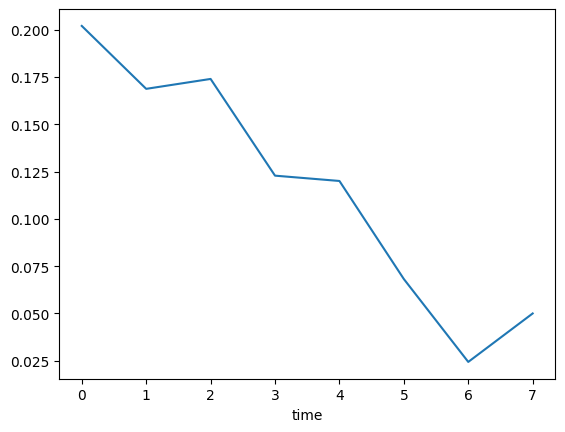

In [152]:
compute_discrete_hazard(processed_df).set_index('time').hazard.plot()

In [153]:
def plot_hazard_by_group(
    df,
    risk_col="risk_crossing",
    split_value=None,
    time_col="time",
    event_col="event_observed"
):
    df = df.copy()

    if split_value is None:
        split_value = df[risk_col].median()

    df["risk_group"] = np.where(
        df[risk_col] >= split_value,
        "High risk",
        "Low risk"
    )

    plt.figure(figsize=(7,5))

    for gname, gdf in df.groupby("risk_group"):
        hz = compute_discrete_hazard(
            gdf,
            time_col=time_col,
            event_col=event_col
        )

        plt.step(
            hz["time"],
            hz["hazard"],
            where="post",
            label=f"{gname} (n={len(gdf)})"
        )

    plt.xlabel("Time since screening")
    plt.ylabel("Hazard rate")
    plt.title("Discrete hazard by risk at threshold crossing")
    plt.legend()
    plt.grid(True)

    return

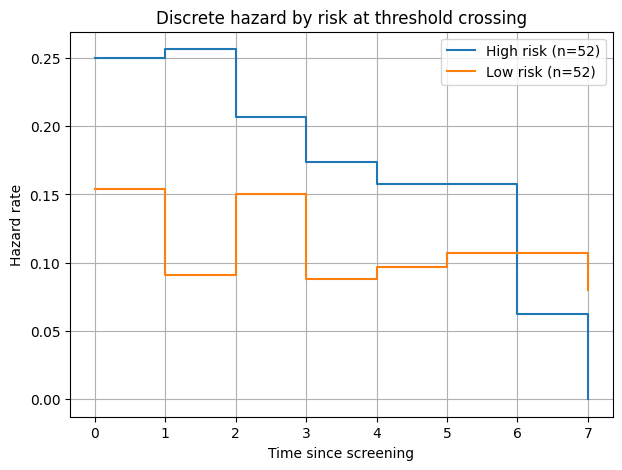

In [154]:
plot_hazard_by_group(processed_df)

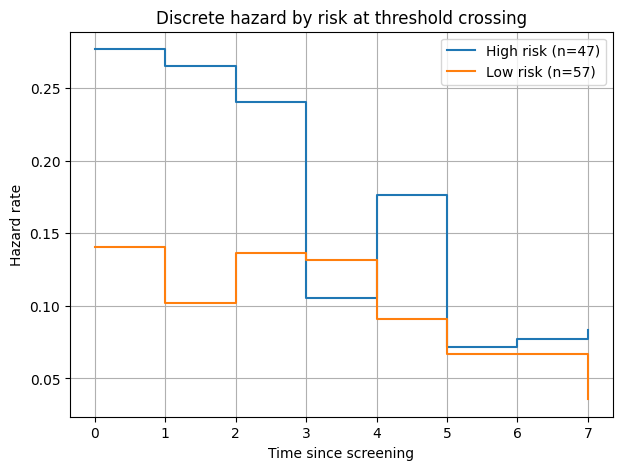

In [157]:
processed_df = add_dynamic_risk_score(processed_df)

plot_hazard_by_group(
    processed_df,
    risk_col="risk_dynamic",
    split_value=processed_df["risk_dynamic"].median()
)

In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def make_screen_event_df_all(
    df,
    risk_threshold,
    patient_col="patient_id",
    month_col="months",
    risk_col="predicted_risk",
    event_date=-1,
    k_list=(1, 3, 6),
):
    """
    Build one row per patient using first threshold crossing as screen_date.

    Output columns include:
      - risk_crossing: risk at first threshold crossing
      - risk_prev_1, risk_prev_3, risk_prev_6
      - delta_1, delta_3, delta_6
      - slope_1, slope_3, slope_6
      - months_above_threshold_to_event
      - mean_risk_to_event
      - max_risk_to_event
      - auc_risk_to_event
      - auc_above_threshold_to_event
      - time_to_event
      - event_observed
    """
    df = df.copy()
    df = df.sort_values([patient_col, month_col]).reset_index(drop=True)

    rows = []

    for pid, g in df.groupby(patient_col, sort=False):
        g = g.sort_values(month_col).reset_index(drop=True)

        crossed = g[g[risk_col] > risk_threshold]
        if crossed.empty:
            continue

        first_idx = crossed.index[0]
        screen_date = g.loc[first_idx, month_col]
        risk_crossing = g.loc[first_idx, risk_col]

        # Restrict from crossing to event_date inclusive
        ge = g[(g[month_col] >= screen_date) & (g[month_col] <= event_date)].copy()
        if ge.empty:
            continue

        # Basic survival quantities
        time_to_event = event_date - screen_date
        event_observed = 1  # in your current case-only setup

        row = {
            patient_col: pid,
            "screen_date": screen_date,
            "event_date": event_date,
            "time": time_to_event,
            "time_to_event": time_to_event,
            "event_observed": event_observed,
            "risk_crossing": risk_crossing,
        }

        # Previous-risk and delta/slope features
        for k in k_list:
            prev_idx = first_idx - k
            risk_prev = g.loc[prev_idx, risk_col] if prev_idx >= 0 else np.nan
            delta_k = risk_crossing - risk_prev if pd.notna(risk_prev) else np.nan
            slope_k = delta_k / k if pd.notna(delta_k) else np.nan

            row[f"risk_prev_{k}"] = risk_prev
            row[f"delta_{k}"] = delta_k
            row[f"slope_{k}"] = slope_k

        # Trajectory summaries from crossing to event
        risks = ge[risk_col].values.astype(float)

        row["months_above_threshold_to_event"] = int((ge[risk_col] > risk_threshold).sum())
        row["frac_months_above_threshold_to_event"] = float((ge[risk_col] > risk_threshold).mean())
        row["mean_risk_to_event"] = float(np.mean(risks))
        row["max_risk_to_event"] = float(np.max(risks))
        row["min_risk_to_event"] = float(np.min(risks))
        row["auc_risk_to_event"] = float(np.sum(risks))
        row["auc_above_threshold_to_event"] = float(np.sum(np.clip(risks - risk_threshold, 0, None)))

        # Optional "dynamic" composite scores
        # Raw versions first; z-scored versions added later across patients
        row["dynamic_raw_1"] = np.nan
        row["dynamic_raw_3"] = np.nan
        row["dynamic_raw_6"] = np.nan

        if pd.notna(row.get("delta_1", np.nan)):
            row["dynamic_raw_1"] = row["risk_crossing"] + row["delta_1"]
        if pd.notna(row.get("delta_3", np.nan)):
            row["dynamic_raw_3"] = row["risk_crossing"] + row["delta_3"]
        if pd.notna(row.get("delta_6", np.nan)):
            row["dynamic_raw_6"] = row["risk_crossing"] + row["delta_6"]

        rows.append(row)

    out = pd.DataFrame(rows)

    # Add cohort-normalized composite dynamic scores
    def zsafe(x):
        x = x.astype(float)
        s = x.std(ddof=0)
        if pd.isna(s) or s == 0:
            return pd.Series(np.zeros(len(x)), index=x.index)
        return (x - x.mean()) / s

    out["risk_crossing_z"] = zsafe(out["risk_crossing"])

    for k in k_list:
        if f"delta_{k}" in out.columns:
            out[f"delta_{k}_z"] = zsafe(out[f"delta_{k}"])
            out[f"slope_{k}_z"] = zsafe(out[f"slope_{k}"])
            out[f"dynamic_z_{k}"] = out["risk_crossing_z"] + out[f"delta_{k}_z"]

    return out


def compute_discrete_hazard(df, time_col="time", event_col="event_observed", max_time=None):
    """
    Discrete hazard:
      h(t) = #events at t / #at risk just before t
    """
    d = df.copy()

    if max_time is None:
        max_time = int(np.nanmax(d[time_col]))

    times = np.arange(0, max_time + 1)

    rows = []
    for t in times:
        n_risk = int((d[time_col] >= t).sum())
        n_events = int(((d[time_col] == t) & (d[event_col] == 1)).sum())
        hazard = n_events / n_risk if n_risk > 0 else np.nan

        rows.append({
            "time": t,
            "at_risk": n_risk,
            "events": n_events,
            "hazard": hazard
        })

    hz = pd.DataFrame(rows)
    hz["cum_hazard"] = hz["hazard"].fillna(0).cumsum()
    return hz


def add_group_by_split(df, risk_col, split_value=None, high_label="High risk", low_label="Low risk"):
    d = df.copy()
    if split_value is None:
        split_value = d[risk_col].median()
    d["risk_group"] = np.where(d[risk_col] >= split_value, high_label, low_label)
    return d, split_value


def add_group_by_quantiles(df, risk_col, q=4):
    d = df.copy()
    valid = d[risk_col].notna()
    d.loc[valid, "risk_group"] = pd.qcut(
        d.loc[valid, risk_col],
        q=q,
        duplicates="drop"
    )
    d["risk_group"] = d["risk_group"].astype(str)
    return d


def plot_hazard_by_group(
    df,
    risk_col="risk_crossing",
    split_value=None,
    time_col="time",
    event_col="event_observed",
    max_time=None,
    smooth_window=None,
    title=None,
):
    d, split_value = add_group_by_split(df, risk_col=risk_col, split_value=split_value)

    plt.figure(figsize=(8, 5))

    for gname, gdf in d.groupby("risk_group"):
        hz = compute_discrete_hazard(gdf, time_col=time_col, event_col=event_col, max_time=max_time)

        y = hz["hazard"].copy()
        if smooth_window is not None and smooth_window > 1:
            y = y.rolling(window=smooth_window, min_periods=1).mean()

        plt.step(hz["time"], y, where="post", label=f"{gname} (n={len(gdf)})")

    plt.xlabel("Time since screening")
    plt.ylabel("Hazard rate")
    plt.title(title or f"Discrete hazard by {risk_col} split at {split_value:.4f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


def plot_cumulative_hazard_by_group(
    df,
    risk_col="risk_crossing",
    split_value=None,
    time_col="time",
    event_col="event_observed",
    max_time=None,
    title=None,
):
    d, split_value = add_group_by_split(df, risk_col=risk_col, split_value=split_value)

    plt.figure(figsize=(8, 5))

    for gname, gdf in d.groupby("risk_group"):
        hz = compute_discrete_hazard(gdf, time_col=time_col, event_col=event_col, max_time=max_time)
        plt.step(hz["time"], hz["cum_hazard"], where="post", label=f"{gname} (n={len(gdf)})")

    plt.xlabel("Time since screening")
    plt.ylabel("Cumulative hazard")
    plt.title(title or f"Cumulative hazard by {risk_col} split at {split_value:.4f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


def plot_hazard_by_quantiles(
    df,
    risk_col="risk_crossing",
    q=4,
    time_col="time",
    event_col="event_observed",
    max_time=None,
    smooth_window=None,
    title=None,
):
    d = add_group_by_quantiles(df, risk_col=risk_col, q=q)

    plt.figure(figsize=(8, 5))

    # sort groups by lower bound if possible
    groups = sorted(d["risk_group"].dropna().unique())

    for gname in groups:
        gdf = d[d["risk_group"] == gname]
        if len(gdf) == 0:
            continue

        hz = compute_discrete_hazard(gdf, time_col=time_col, event_col=event_col, max_time=max_time)
        y = hz["hazard"].copy()
        if smooth_window is not None and smooth_window > 1:
            y = y.rolling(window=smooth_window, min_periods=1).mean()

        plt.step(hz["time"], y, where="post", label=f"{gname} (n={len(gdf)})")

    plt.xlabel("Time since screening")
    plt.ylabel("Hazard rate")
    plt.title(title or f"Discrete hazard by quantiles of {risk_col}")
    plt.grid(True, alpha=0.3)
    plt.legend(title=risk_col, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def summarize_early_late_hazard(
    df,
    risk_col="risk_crossing",
    split_value=None,
    time_col="time",
    event_col="event_observed",
    early_window=(0, 2),
    late_window=(3, 6),
):
    d, split_value = add_group_by_split(df, risk_col=risk_col, split_value=split_value)

    out_rows = []
    for gname, gdf in d.groupby("risk_group"):
        hz = compute_discrete_hazard(gdf, time_col=time_col, event_col=event_col)

        e0, e1 = early_window
        l0, l1 = late_window

        early_mean = hz.loc[(hz["time"] >= e0) & (hz["time"] <= e1), "hazard"].mean()
        late_mean = hz.loc[(hz["time"] >= l0) & (hz["time"] <= l1), "hazard"].mean()

        out_rows.append({
            "risk_group": gname,
            "n": len(gdf),
            "split_value": split_value,
            "early_mean_hazard": early_mean,
            "late_mean_hazard": late_mean,
            "early_late_ratio": early_mean / late_mean if pd.notna(late_mean) and late_mean > 0 else np.nan
        })

    return pd.DataFrame(out_rows)

['patient_id', 'screen_date', 'event_date', 'time', 'time_to_event', 'event_observed', 'risk_crossing', 'risk_prev_1', 'delta_1', 'slope_1', 'risk_prev_3', 'delta_3', 'slope_3', 'risk_prev_6', 'delta_6', 'slope_6', 'months_above_threshold_to_event', 'frac_months_above_threshold_to_event', 'mean_risk_to_event', 'max_risk_to_event', 'min_risk_to_event', 'auc_risk_to_event', 'auc_above_threshold_to_event', 'dynamic_raw_1', 'dynamic_raw_3', 'dynamic_raw_6', 'risk_crossing_z', 'delta_1_z', 'slope_1_z', 'dynamic_z_1', 'delta_3_z', 'slope_3_z', 'dynamic_z_3', 'delta_6_z', 'slope_6_z', 'dynamic_z_6']
    patient_id  screen_date  event_date  time  time_to_event  event_observed  \
0    1018601.0           -1          -1     0              0               1   
1   27783001.0           -5          -1     4              4               1   
2  139646401.0          -21          -1    20             20               1   
3  212615001.0           -1          -1     0              0               1   


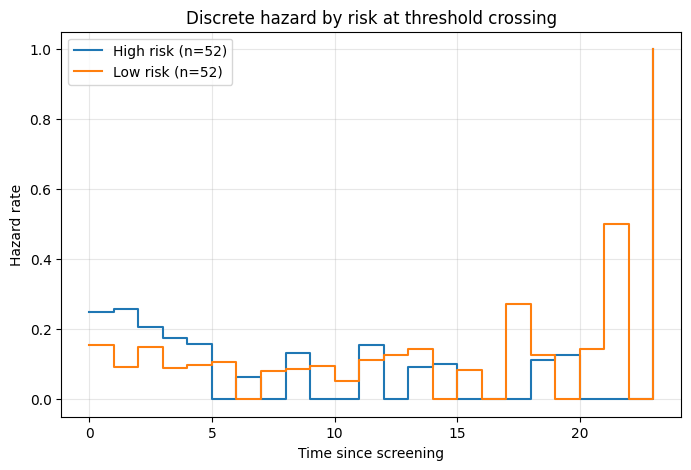

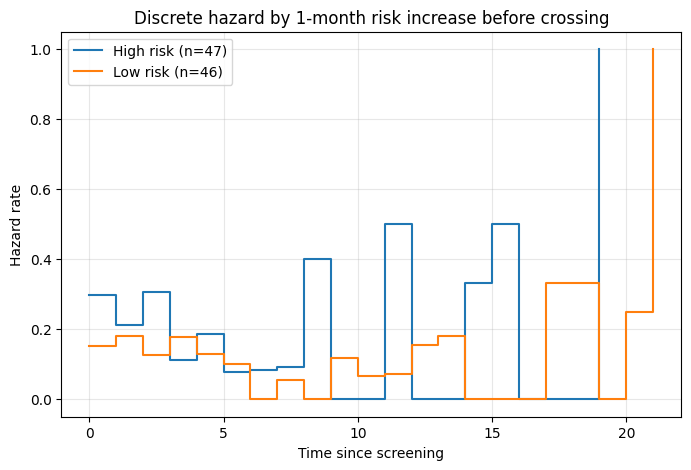

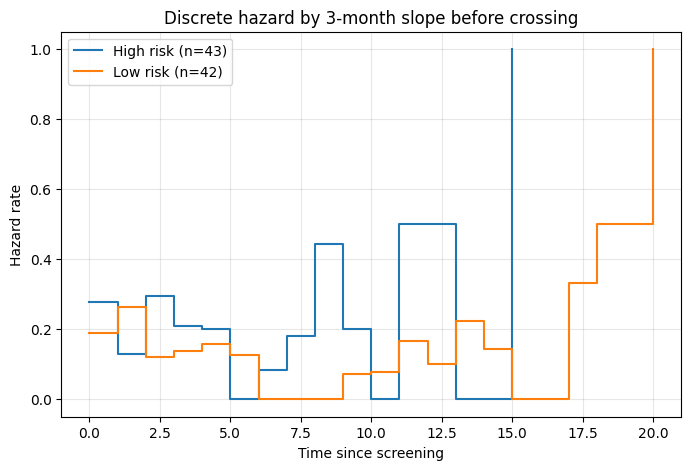

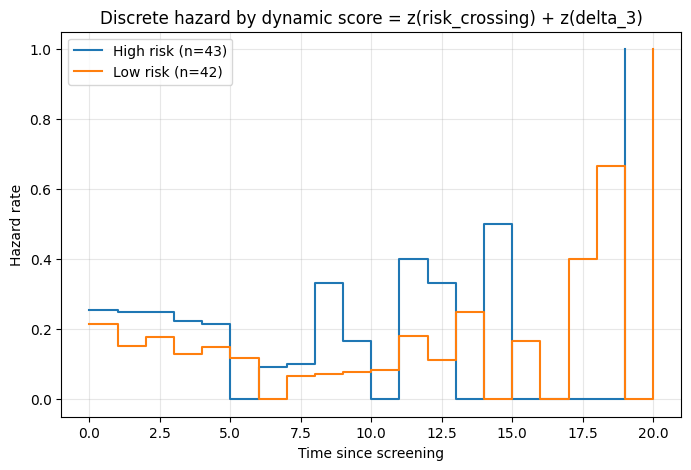

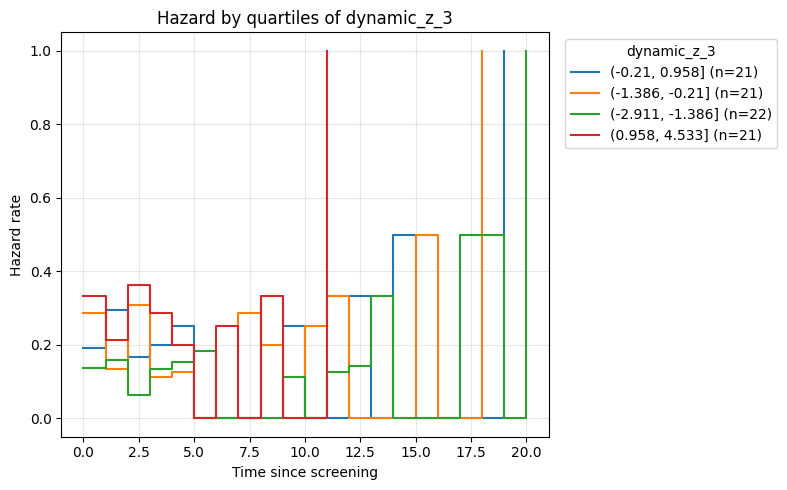

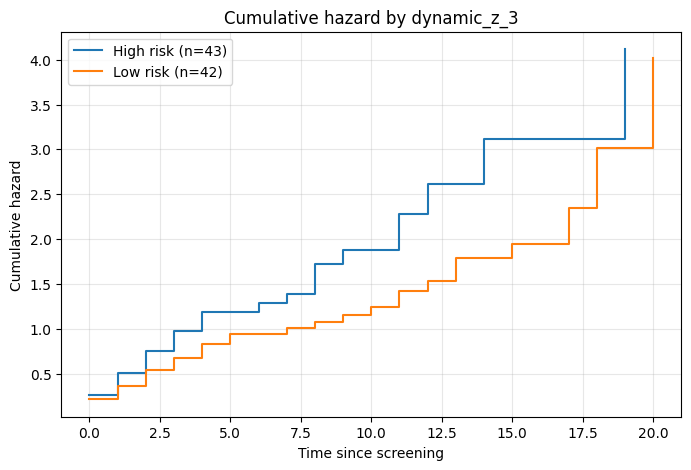

  risk_group   n  split_value  early_mean_hazard  late_mean_hazard  \
0  High risk  43    -0.210125           0.251938          0.131854   
1   Low risk  42    -0.210125           0.181457          0.099520   

   early_late_ratio  
0          1.910731  
1          1.823318  


In [163]:
# -------------------------
# Example usage
# -------------------------

# Build patient-level screening dataframe
#TH99 = your 99% specificity threshold
processed_df = make_screen_event_df_all(df, risk_threshold=TH99)

# Look at columns
print(processed_df.columns.tolist())
print(processed_df.head())

# 1) Hazard by risk level at threshold crossing
plot_hazard_by_group(
     processed_df,
     risk_col="risk_crossing",
     split_value=processed_df["risk_crossing"].median(),
     title="Discrete hazard by risk at threshold crossing"
 )

# 2) Hazard by 1-month increase before crossing
plot_hazard_by_group(
     processed_df.dropna(subset=["delta_1"]),
     risk_col="delta_1",
     split_value=processed_df["delta_1"].median(),
     title="Discrete hazard by 1-month risk increase before crossing"
 )

# 3) Hazard by 3-month slope before crossing
plot_hazard_by_group(
     processed_df.dropna(subset=["slope_3"]),
     risk_col="slope_3",
     split_value=processed_df["slope_3"].median(),
     title="Discrete hazard by 3-month slope before crossing"
 )

# 4) Hazard by normalized dynamic composite
plot_hazard_by_group(
     processed_df.dropna(subset=["dynamic_z_3"]),
     risk_col="dynamic_z_3",
     split_value=processed_df["dynamic_z_3"].median(),
     title="Discrete hazard by dynamic score = z(risk_crossing) + z(delta_3)"
 )

# 5) Quantile-based hazard plot
plot_hazard_by_quantiles(
     processed_df.dropna(subset=["dynamic_z_3"]),
     risk_col="dynamic_z_3",
     q=4,
     title="Hazard by quartiles of dynamic_z_3"
 )

# 6) Cumulative hazard
plot_cumulative_hazard_by_group(
     processed_df.dropna(subset=["dynamic_z_3"]),
     risk_col="dynamic_z_3",
     split_value=processed_df["dynamic_z_3"].median(),
     title="Cumulative hazard by dynamic_z_3"
 )

# 7) Early vs late hazard summary
summary = summarize_early_late_hazard(
     processed_df.dropna(subset=["dynamic_z_3"]),
     risk_col="dynamic_z_3",
     split_value=processed_df["dynamic_z_3"].median(),
     early_window=(0, 2),
     late_window=(3, 6),
 )
print(summary)